# Systemy AI – Laboratorium 3
## Titanic: wybieranie danych, braki, tabele przestawne i pierwszy klasyfikator

**Cel:** przygotować prawdziwy zbiór danych do modelowania (wybieranie wierszy i kolumn, braki danych, grupowanie), zwizualizować go i zbudować pierwszy klasyfikator, który „uczy się” z danych.


---
## Przygotowanie

Komórka poniżej wczytuje biblioteki i dane oraz definiuje funkcję `binary_metrics` z Lab 1 (tym razem gotową). Uruchom ją i nic w niej nie zmieniaj.

Zbiór opisuje 891 pasażerów Titanica. Zadanie klasyfikacji binarnej: przewidzieć kolumnę `survived`.

| Kolumna | Znaczenie |
|---|---|
| `survived` | **etykieta**: 1 = przeżył/a, 0 = nie |
| `pclass` | klasa podróży: 1, 2 lub 3 |
| `sex` | płeć: `"male"` / `"female"` |
| `age` | wiek w latach (są braki!) |
| `fare` | cena biletu |
| `embarked` | port zaokrętowania: S = Southampton, C = Cherbourg, Q = Queenstown (są braki!) |

In [97]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("titanic")
df = df[["survived", "pclass", "sex", "age", "fare", "embarked"]].copy()


def binary_metrics(y_true, y_pred):
    """Metryki klasyfikacji binarnej (z Lab 1). Metryka z zerowym mianownikiem = 0.0."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    TP = int(np.sum((y_true == 1) & (y_pred == 1)))
    FP = int(np.sum((y_true == 0) & (y_pred == 1)))
    FN = int(np.sum((y_true == 1) & (y_pred == 0)))
    TN = int(np.sum((y_true == 0) & (y_pred == 0)))
    div = lambda a, b: a / b if b > 0 else 0.0
    precision, recall = div(TP, TP + FP), div(TP, TP + FN)
    return {"TP": TP, "FP": FP, "FN": FN, "TN": TN,
            "accuracy": div(TP + TN, len(y_true)), "precision": precision,
            "recall": recall, "f1": div(2 * precision * recall, precision + recall)}


print(df.shape)
df.head()

(891, 6)


,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


---
## Część A. pandas: `loc` i `iloc`

Wiersze i kolumny `DataFrame` można wybierać na dwa sposoby:

| | `df.iloc[...]` | `df.loc[...]` |
|---|---|---|
| wybiera po | **pozycji** (0, 1, 2, …), jak w liście | **etykiecie** indeksu i **nazwie** kolumny |
| przykład | `df.iloc[0, 3]` – 1. wiersz, 4. kolumna | `df.loc[0, "age"]` – wiersz o indeksie 0, kolumna `age` |
| wycinek `5:7` | wiersze na pozycjach 5 i 6 (**bez** 7) | wiersze o etykietach 5, 6 **i 7** |
| warunek logiczny | nie | tak: `df.loc[df["age"] < 10, "survived"]` |

Warunki łączymy operatorami `&` (i), `|` (lub), `~` (nie), a **każdy warunek bierzemy w nawias**:
`df.loc[(df["sex"] == "female") & (df["pclass"] == 3)]`.

Zaraz po wczytaniu indeks to 0, 1, 2, …, więc pozycja i etykieta są takie same. Różnica wychodzi po filtrowaniu albo sortowaniu: wtedy indeks ma „dziury” i `iloc[0]` nie jest już wierszem o etykiecie 0.

### Zadanie A1. Wybieranie danych
1. `first_row` – pierwszy wiersz tabeli (`iloc`).
2. `corner` – pierwsze 5 wierszy i pierwsze 3 kolumny (`iloc`).
3. `ages_5_7` – kolumna `age` dla wierszy o etykietach od 5 do 7 włącznie (`loc`).
4. `women3` – wszystkie kobiety podróżujące 3. klasą (`loc` z warunkiem) oraz `p_women3` – odsetek ocalałych w tej grupie.
5. `old_fare` – ceny biletów (tylko kolumna `fare`) pasażerów w wieku powyżej 70 lat.

W komentarzu: ile wierszy zwraca `df.iloc[5:7]`, a ile `df.loc[5:7]`? Dlaczego?

In [98]:
# Twoje rozwiązanie

first_row = df.iloc[0]
corner = df.iloc[:5, :3]
ages_5_7 = df.loc[5:7, "age"]
women3 = df.loc[(df["sex"] == "female") & (df["pclass"] == 3)]
p_women3 = women3["survived"].mean()
old_fare = df.loc[df["age"] > 70, "fare"]


print(len(df.iloc[5:7]), len(df.loc[5:7]))

#df.iloc zwraca 2 wiersze, a df.loc 3 wiersze. Różnica w wynikach wychodzi ze sposobu działania funkcji. iloc bierze 5 i 6, a loc wybiera wiersze z wycinka uwzględniając też ten końcowy.

2 3


In [99]:
# TEST
assert first_row["age"] == 22.0 and first_row["sex"] == "male"
assert corner.shape == (5, 3) and list(corner.columns) == ["survived", "pclass", "sex"]
assert list(ages_5_7.index) == [5, 6, 7]
assert len(women3) == 144 and abs(p_women3 - 0.5) < 1e-9
assert len(old_fare) == 5 and old_fare.name == "fare"
print("A1 OK")

A1 OK


---
## Część B. Braki danych

Brakująca wartość w pandas to `NaN` (*Not a Number*). Większość modeli uczenia maszynowego **nie przyjmie** tabeli z brakami, więc trzeba je wykryć i coś z nimi zrobić.

| Strategia | Kod | Kiedy | Wada |
|---|---|---|---|
| usuń wiersze | `df.dropna(subset=["age"])` | braków jest bardzo mało | tracimy dane; jeśli braki nie są losowe, zbiór staje się stronniczy |
| średnia | `s.fillna(s.mean())` | rozkład symetryczny, bez wartości odstających | wrażliwa na wartości odstające |
| mediana | `s.fillna(s.median())` | rozkład skośny lub z wartościami odstającymi | wszystkie braki dostają tę samą wartość |
| moda | `s.fillna(s.mode()[0])` | cechy **kategoryczne** (np. port) | wzmacnia najczęstszą kategorię |
| mediana w grupach | `s.fillna(df.groupby(["sex", "pclass"])["age"].transform("median"))` | wartość zależy od innych cech | trochę więcej kodu |
| flaga braku | `df["age_missing"] = df["age"].isna().astype(int)` | sam fakt braku może coś znaczyć | dodatkowa kolumna |

Każde uzupełnienie to **zgadywanie**. Uzupełnione wartości nie są pomiarami, tylko naszym założeniem, i zmniejszają zmienność danych.

**Najważniejsze pytanie:** czy braki są losowe? Jeśli wiek częściej brakuje u pasażerów 3. klasy, to braki niosą informację, a usunięcie tych wierszy zmienia strukturę zbioru.

### Zadanie B1. Gdzie są braki i czy są losowe?
1. `missing` – liczba braków w każdej kolumnie (`isna().sum()`).
2. `frac_age` – jaki **ułamek** wierszy nie ma wieku (`isna().mean()`).
3. `miss_by_class` – ułamek braków wieku w każdej klasie podróży (pogrupuj po `pclass` kolumnę `df["age"].isna()`).
4. `surv_by_missing` – odsetek ocalałych wśród osób **z** podanym wiekiem i **bez** niego (`df.groupby(df["age"].isna())["survived"].mean()`).

In [100]:
# Twoje rozwiązanie

missing = df.isna().sum()
frac_age = df["age"].isna().mean()
miss_by_class = df["age"].isna().groupby(df["pclass"]).mean()
surv_by_missing = df.groupby(df["age"].isna())["survived"].mean()

print(missing)
print(frac_age)
print(miss_by_class)
print(surv_by_missing)

survived      0
pclass        0
sex           0
age         177
fare          0
embarked      2
dtype: int64
0.19865319865319866
pclass
1    0.138889
2    0.059783
3    0.276986
Name: age, dtype: float64
age
False    0.406162
True     0.293785
Name: survived, dtype: float64


In [101]:
# TEST
assert missing["age"] == 177 and missing["embarked"] == 2 and missing["fare"] == 0
assert abs(frac_age - 0.1987) < 1e-3
assert abs(miss_by_class[3] - 0.277) < 1e-3 and abs(miss_by_class[2] - 0.060) < 1e-3
assert abs(surv_by_missing[True] - 0.294) < 1e-3 and abs(surv_by_missing[False] - 0.406) < 1e-3
print("B1 OK")

B1 OK


*Twoja odpowiedź:* czy braki wieku są losowe? Uzasadnij liczbami.

Nie są to do końca losowe braki. Można to wywnioskować po zależności od klasy podróży, gdzie w 1 klasie brakowało około 13,9% danych, w drugiej - ok. 6%, trzeciej - ok. 27,7%, co może wskazywać na korelację między statusem społecznym a odnotowaniem wieku.

### Zadanie B2. Porównanie strategii
Przygotuj cztery wersje kolumny `age`:
- `age_drop` – braki usunięte (`dropna()`),
- `age_mean` – braki uzupełnione średnią,
- `age_median` – braki uzupełnione medianą,
- `age_group` – braki uzupełnione medianą wieku **w grupie (płeć, klasa)** (`groupby(...)["age"].transform("median")`; `transform` zwraca wartość grupy dla każdego wiersza, więc wynik ma tyle samo wierszy co `df`).

Zbierz w tabeli `cmp` (wiersze: `drop`, `mean`, `median`, `group`) kolumny `n` (liczba wartości), `mean` i `std`.

Następnie porównaj średnią i medianę **ceny biletu** (`fare`): zapisz je w `fare_mean` i `fare_median`.

In [102]:
# Twoje rozwiązanie

age_drop = df["age"].dropna()
age_mean = df["age"].fillna(df["age"].mean())
age_median = df["age"].fillna(df["age"].median())
age_group = df["age"].fillna(df.groupby(["sex", "pclass"])["age"].transform("median"))

cmp = pd.DataFrame(index=["drop", "mean", "median", "group"], columns=["n", "mean", "std"])

for name, s in zip(["drop", "mean", "median", "group"], [age_drop, age_mean, age_median, age_group]):
    cmp.loc[name, "n"] = len(s)
    cmp.loc[name, "mean"] = s.mean()
    cmp.loc[name, "std"] = s.std()

cmp["n"] = cmp["n"].astype(int)
cmp["mean"] = cmp["mean"].astype(float)
cmp["std"] = cmp["std"].astype(float)

fare_mean = df["fare"].mean()
fare_median = df["fare"].median()

print(cmp)
print(f"\nFare mean: {fare_mean}, Fare median: {fare_median}")

          n       mean        std
drop    714  29.699118  14.526497
mean    891  29.699118  13.002015
median  891  29.361582  13.019697
group   891  29.112424  13.304424

Fare mean: 32.204207968574636, Fare median: 14.4542


In [103]:
# TEST
assert list(cmp.index) == ["drop", "mean", "median", "group"]
assert list(cmp["n"]) == [714, 891, 891, 891]
assert abs(cmp.loc["median", "mean"] - 29.362) < 1e-2 and abs(cmp.loc["group", "mean"] - 29.112) < 1e-2
assert abs(cmp.loc["drop", "std"] - 14.526) < 1e-2 and abs(cmp.loc["mean", "std"] - 13.002) < 1e-2
assert abs(fare_mean - 32.20) < 1e-2 and fare_median == 14.4542
print("B2 OK")

B2 OK


*Twoja odpowiedź:*
1. Dlaczego po uzupełnieniu (średnią lub medianą) odchylenie standardowe wieku spada?

Ponieważ wprowadzamy jedną wartość, a odchylenie standardowe wskazuje jak bardzo różnorodne dane posiadamy.

2. Dla ceny biletu średnia i mediana bardzo się różnią. Dlaczego? Którą wartością uzupełnił(a)byś braki w `fare`?

Jest to spowodowane tym, że mamy wiele osób, co zapłaciły za bilet niewiele, ale też są te zamożne, które dużo za niego dały. Braki lepiej uzupełnić medianą, gdyż oscyluje w kwotach za bilet większości pasażerów.

3. Która strategia dla `age` wydaje Ci się najrozsądniejsza i dlaczego?

Najrozsądniejsza myślę, że będzie mediana w grupach, gdyż pozwala na utrzymanie bardziej rzeczywistych korelacji cech danych w poszczególnych grupach.

### Zadanie B3. Czysty zbiór
Utwórz `df_clean = df.copy()` i w nim:
1. dodaj kolumnę `age_missing` (1, jeśli wiek był brakujący, w przeciwnym razie 0) – **zanim** uzupełnisz braki;
2. uzupełnij `age` medianą w grupach (płeć, klasa);
3. uzupełnij `embarked` **modą**.

Na koniec sprawdź, że w `df_clean` nie ma już żadnych braków. Od tej chwili pracujemy na `df_clean`.

In [104]:
# Twoje rozwiązanie

df_clean = df.copy()
df_clean["age_missing"] = df_clean["age"].isna().astype(int)
df_clean["age"] = df_clean["age"].fillna(df_clean.groupby(["sex", "pclass"])["age"].transform("median"))
df_clean["embarked"] = df_clean["embarked"].fillna(df_clean["embarked"].mode()[0])

print(df_clean.isna().sum())
print(df_clean["age"].mean())

survived       0
pclass         0
sex            0
age            0
fare           0
embarked       0
age_missing    0
dtype: int64
29.11242424242424


In [105]:
# TEST
assert df_clean.isna().sum().sum() == 0, "W df_clean są jeszcze braki"
assert df_clean["age_missing"].sum() == 177, "Flagę braku trzeba dodać przed uzupełnieniem"
assert df["age"].isna().sum() == 177, "Oryginalny df nie powinien się zmienić - użyj .copy()"
assert df_clean["embarked"].value_counts()["S"] == 646
assert abs(df_clean["age"].mean() - 29.112) < 1e-2
print("B3 OK")

B3 OK


---
## Część C. Grupowanie i tabela przestawna

`groupby` działa w trzech krokach: **podziel** wiersze na grupy → **policz** coś w każdej grupie → **złóż** wyniki w tabelę.

Średnia z kolumny 0/1 to odsetek jedynek, więc `df_clean.groupby("sex")["survived"].mean()` to odsetek ocalałych w każdej płci.

**Tabela przestawna** (`pivot_table`) to grupowanie po **dwóch** cechach naraz, ułożone w siatkę: jedna cecha w wierszach, druga w kolumnach, a w komórkach wynik funkcji `aggfunc` (np. `"mean"`, `"count"`, `"median"`):

```python
df_clean.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="mean")
```

### Zadanie C1. Kto przeżył?
1. `surv_by_sex` – odsetek ocalałych według płci.
2. `surv_by_class` – odsetek ocalałych według klasy.
3. `pivot` – tabela przestawna: wiersze `sex`, kolumny `pclass`, wartości: odsetek ocalałych.
4. `pivot_n` – ta sama tabela, ale z **liczbą pasażerów** w każdej komórce (`aggfunc="count"`).

In [106]:
# Twoje rozwiązanie
surv_by_sex = df_clean.groupby("sex")["survived"].mean()
surv_by_class = df_clean.groupby("pclass")["survived"].mean()
pivot = df_clean.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="mean")
pivot_n = df_clean.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="count")

print(surv_by_sex)
print()
print(surv_by_class)
print()
print(pivot)
print()
print(pivot_n)

sex
female    0.742038
male      0.188908
Name: survived, dtype: float64

pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64

pclass         1         2         3
sex                                 
female  0.968085  0.921053  0.500000
male    0.368852  0.157407  0.135447

pclass    1    2    3
sex                  
female   94   76  144
male    122  108  347


In [107]:
# TEST
assert abs(surv_by_sex["female"] - 0.742) < 1e-3 and abs(surv_by_sex["male"] - 0.189) < 1e-3
assert abs(surv_by_class[1] - 0.630) < 1e-3 and abs(surv_by_class[3] - 0.242) < 1e-3
assert abs(pivot.loc["female", 1] - 0.968) < 1e-3 and abs(pivot.loc["male", 3] - 0.135) < 1e-3
assert pivot_n.loc["female", 3] == 144 and pivot_n.values.sum() == 891
print("C1 OK")

C1 OK


*Twoja odpowiedź:* która cecha lepiej rozdziela ocalałych od ofiar: płeć czy klasa? Która grupa z tabeli przestawnej odstaje od reguły „kobiety przeżyły”? Dlaczego warto patrzeć też na `pivot_n`?

Lepiej płeć rozdziela ocalałych od ofiar. Odstaje grupa kobiet w 3 klasie. Pivot_n pozwala nam na szersze spojrzenie na dane, gdyż sama średnia może nie być wystarczająca, gdy liczebność grup jest mała.

---
## Część D. Wykresy: `plt.subplots` i seaborn

```python
fig, axes = plt.subplots(1, 2, figsize=(12, 5))   # 1 wiersz, 2 kolumny wykresów, rozmiar w calach
```
- `fig` to cały rysunek (zapisujemy go `fig.savefig(...)`),
- `axes` to tablica układów współrzędnych: `axes[0]` po lewej, `axes[1]` po prawej.

**seaborn** to nakładka na matplotlib dla danych w `DataFrame`: podajesz tabelę (`data=`), nazwy kolumn (`x=`, `y=`, `hue=` – kolor wg kategorii) i **na którym wykresie rysować** (`ax=`).

| Funkcja | Co rysuje |
|---|---|
| `sns.histplot(data=df, x="age", hue="survived", ax=...)` | histogram, osobno dla każdej wartości `hue` |
| `sns.countplot(data=df, x="pclass", hue="survived", ax=...)` | liczba wierszy w każdej kategorii |
| `sns.barplot(data=df, x="pclass", y="survived", hue="sex", ax=...)` | **średnia** `y` w każdej kategorii + pionowa kreska: przedział ufności |

### Zadanie D1. Jeden rysunek, dwa wykresy
1. Utwórz `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`.
2. Po lewej (`axes[0]`): `sns.histplot` wieku z `df_clean`, 20 przedziałów, kolor według `survived`.
3. Po prawej (`axes[1]`): `sns.barplot` odsetka ocalałych według klasy, z podziałem na płeć (`hue="sex"`). Dodaj poziomą przerywaną linię na wysokości ogólnego odsetka ocalałych (`axes[1].axhline(...)`).
4. Każdemu wykresowi nadaj tytuł i podpisz osie (`set_title`, `set_xlabel`, `set_ylabel`). Zapisz rysunek do `titanic.png` (`fig.savefig("titanic.png", dpi=150)`).

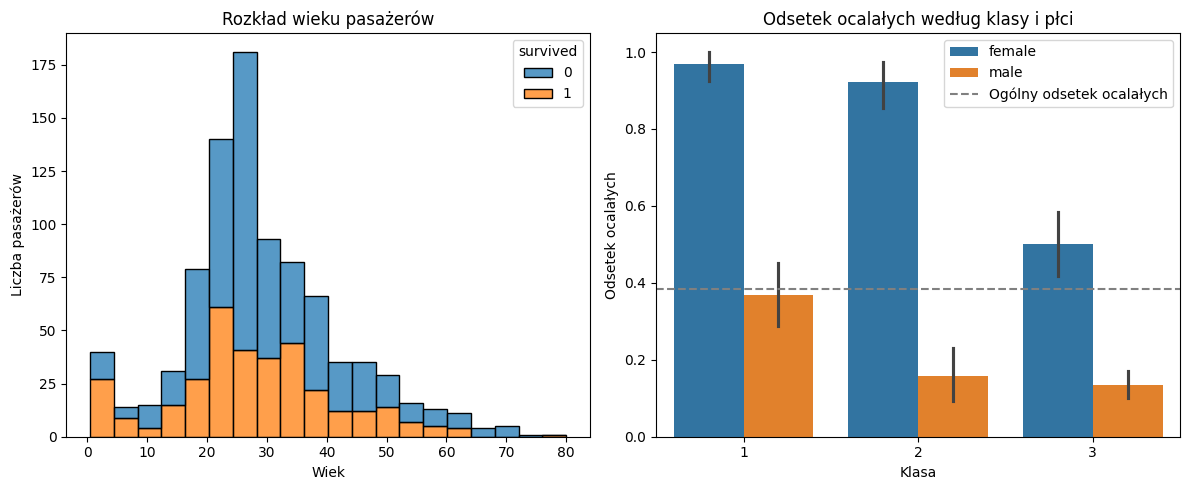

In [108]:
#Twoje rozwiązanie

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(data=df_clean, x="age", hue="survived", bins=20, multiple="stack", ax=axes[0])
axes[0].set_title("Rozkład wieku pasażerów")
axes[0].set_xlabel("Wiek")
axes[0].set_ylabel("Liczba pasażerów")

sns.barplot(data=df_clean, x="pclass", y="survived", hue="sex", ax=axes[1])
axes[1].axhline(df_clean["survived"].mean(), color="gray", linestyle="--", label="Ogólny odsetek ocalałych")
axes[1].set_title("Odsetek ocalałych według klasy i płci")
axes[1].set_xlabel("Klasa")
axes[1].set_ylabel("Odsetek ocalałych")
axes[1].legend()

plt.tight_layout()
fig.savefig("titanic.png", dpi=150)
plt.show()

In [109]:
# TEST
import os
assert len(fig.axes) >= 2, "Rysunek powinien mieć dwa wykresy"
assert os.path.exists("titanic.png") and os.path.getsize("titanic.png") > 5000
assert all(ax.get_title() for ax in fig.axes[:2]), "Brakuje tytułów wykresów"
print("D1 OK")

D1 OK


*Twoja odpowiedź:* na histogramie słupki w okolicach 20–30 lat są wyraźnie wyższe od sąsiednich. Skąd się wzięły? Jak wyglądałby histogram, gdyby braki uzupełnić jedną medianą?

Są wyraźnie wyższe, gdyż wartości wieku zostały uzupełnione o medianę odpowiadających grup. Jeżeli uzupełniłoby się jedną medianą, to będzie jeden bardzo odstający od reszty pik.

---
## Część E. Pierwszy klasyfikator

Porównamy trzy klasyfikatory:

1. **Baseline „nikt nie przeżył”** – zawsze 0. To punkt odniesienia: każdy sensowny model musi być od niego lepszy.
2. **Reguła „kobieta → 1”** – wymyślona przez człowieka.
3. **Klasyfikator z tabeli przestawnej** – reguła **wyznaczona z danych**: dla każdej grupy (płeć, klasa) odczytujemy z `pivot` odsetek ocalałych i przewidujemy 1, jeśli przekracza 0.5. To najprostsza forma uczenia: model „zapamiętuje”, co zwykle działo się w danej grupie.

Do przypisania każdemu pasażerowi wartości jego grupy przyda się `transform` (jak w B2):
```python
rate = df_clean.groupby(["sex", "pclass"])["survived"].transform("mean")   # wartość z pivot dla każdego wiersza
```

### Zadanie E1. Trzy klasyfikatory
1. `y` – kolumna `survived` jako tablica NumPy (`to_numpy()`).
2. `y_zero`, `y_rule`, `y_pivot` – predykcje trzech klasyfikatorów (tablice liczb całkowitych 0/1).
3. `m_zero`, `m_rule`, `m_pivot` – ich metryki (`binary_metrics`).
4. `df_models` – tabela z wierszami `"zawsze-zero"`, `"kobieta → 1"`, `"tabela przestawna"` i kolumnami `TP`, `FP`, `FN`, `TN`, `accuracy`, `precision`, `recall`, `f1`.
5. Sprawdź jeden z wyników funkcją `classification_report` ze `sklearn.metrics`.

In [110]:
from sklearn.metrics import classification_report

# Twoje rozwiązanie
y = df_clean["survived"].to_numpy()

y_zero = np.zeros(len(df_clean), dtype=int)

y_rule = (df_clean["sex"] == "female").astype(int).to_numpy()

rate = df_clean.groupby(["sex", "pclass"])["survived"].transform("mean")
y_pivot = (rate > 0.5).astype(int).to_numpy()

m_zero = binary_metrics(y, y_zero)
m_rule = binary_metrics(y, y_rule)
m_pivot = binary_metrics(y, y_pivot)

df_models = pd.DataFrame(
    [m_zero, m_rule, m_pivot],
    index=["zawsze-zero", "kobieta → 1", "tabela przestawna"]
)

print(df_models)
print()
print(classification_report(y, y_pivot))

                    TP  FP   FN   TN  accuracy  precision    recall        f1
zawsze-zero          0   0  342  549  0.616162   0.000000  0.000000  0.000000
kobieta → 1        233  81  109  468  0.786756   0.742038  0.681287  0.710366
tabela przestawna  161   9  181  540  0.786756   0.947059  0.470760  0.628906

              precision    recall  f1-score   support

           0       0.75      0.98      0.85       549
           1       0.95      0.47      0.63       342

    accuracy                           0.79       891
   macro avg       0.85      0.73      0.74       891
weighted avg       0.82      0.79      0.77       891



In [111]:
# TEST
assert m_zero["recall"] == 0.0 and abs(m_zero["accuracy"] - 0.6162) < 1e-3
assert (m_rule["TP"], m_rule["FP"], m_rule["FN"], m_rule["TN"]) == (233, 81, 109, 468)
assert (m_pivot["TP"], m_pivot["FP"], m_pivot["FN"], m_pivot["TN"]) == (161, 9, 181, 540)
assert list(df_models.index) == ["zawsze-zero", "kobieta → 1", "tabela przestawna"]
assert {"accuracy", "precision", "recall", "f1"} <= set(df_models.columns)
print("E1 OK")

E1 OK


### Zadanie E2. Wnioski
Odpowiedz krótko, odwołując się do liczb z `df_models`:

1. O ile oba klasyfikatory poprawiają accuracy względem baseline'u? Dlaczego samo „accuracy = 0.79” bez baseline'u niewiele mówi?
2. Reguła „kobieta → 1” i klasyfikator z tabeli przestawnej mają **identyczną** accuracy. Czym się różnią? Kim są osoby, które klasyfikator z tabeli przestawnej „zmienił” w porównaniu z regułą?
3. Który z nich wybrał(a)byś, gdyby fałszywy alarm (FP) był bardzo kosztowny? A gdyby kosztowne było przeoczenie (FN)?
4. Klasyfikator z tabeli przestawnej „nauczył się” na tych samych danych, na których go oceniamy. Dlaczego taka ocena jest zbyt optymistyczna? Co by się stało, gdyby grup było bardzo dużo, a w każdej po kilka osób?
5. Te reguły decydują na podstawie płci. Podaj zastosowanie, w którym taka reguła byłaby niedopuszczalna niezależnie od accuracy, i wyjaśnij dlaczego.

*Twoja odpowiedź:*

Oba klasyfikatory poprawiają accuracy względem baselanu o około 0.17.
Niewiele mówi, gdyż baseline jest punktem odniesienia, aby móc stwierdzić, czy modele sobie radzą.

Różnią się rozkładem odpowiedzi TP, TN, FP, FN. Klasyfikator z tabeli przestawnej, w porównaniu do reguły, zmienił kobiety z 3 klasy.

Kosztowny FP - klasyfikator z tabeli przestawnej
Kosztowny FN - reguła

Następuje wtedy błąd przeuczenia i mimo że klasyfikator zwracał dobre wyniki, nie nastąpiłaby generalizacja informacji. Gdyby było wiele grup po kilka osób, podobnie model by zapamiętał dane, ale na nowych danych, nie poradziłby sobie.

Przykładowo niedopuszczalne byłoby dla systemu rekrutacji, gdyż wprowadziłby niepotrzebną i kontrowersyjną dyskryminację

---
## Część F. Zadania dodatkowe (dla chętnych / do domu)

**F1. Kobiety i dzieci.** Zbuduj regułę „kobieta **lub** dziecko poniżej 10 lat → 1”, policz metryki i dopisz wiersz do `df_models`. Co się poprawiło, a co pogorszyło? Ile dzieci z brakującym wiekiem reguła „przeoczyła”, bo dostały medianę grupy (wskazówka: `age_missing`)?

**F2. Więcej grup = lepiej?** Dodaj kolumnę `age_group` (`pd.cut(df_clean["age"], bins=[0, 10, 18, 40, 60, 100])`) i zbuduj klasyfikator z tabeli przestawnej dla grup (płeć, klasa, `age_group`). Policz accuracy. Ile grup ma mniej niż 10 osób? Wróć do pytania E2.4.

**F3. Próg na cenę biletu.** Potraktuj cenę biletu jako „wynik modelu”: `y_hat = (df_clean["fare"] >= t)`. Dla 50 progów `t` od 0 do 100 policz precision, recall i F1, narysuj krzywe w funkcji `t` (seaborn albo matplotlib). Przy jakim progu F1 jest największe?

In [112]:
# Twoje rozwiązanie
y_f1 = ((df_clean["sex"] == "female") | (df_clean["age"] < 10)).astype(int).to_numpy()
m_f1 = binary_metrics(y, y_f1)
df_models.loc["kobieta lub dziecko < 10"] = m_f1

missed_children_count = len(df_clean[(df_clean["age_missing"]) & (df_clean["age"] >= 10)])

print(df_models)
print()
print(missed_children_count)

                           TP  FP   FN   TN  accuracy  precision    recall  \
zawsze-zero                 0   0  342  549  0.616162   0.000000  0.000000   
kobieta → 1               233  81  109  468  0.786756   0.742038  0.681287   
tabela przestawna         161   9  181  540  0.786756   0.947059  0.470760   
kobieta lub dziecko < 10  252  94   90  455  0.793490   0.728324  0.736842   

                                f1  
zawsze-zero               0.000000  
kobieta → 1               0.710366  
tabela przestawna         0.628906  
kobieta lub dziecko < 10  0.732558  

177


In [113]:
df_clean["age_group"] = pd.cut(df_clean["age"], bins=[0, 10, 18, 40, 60, 100])

rate_f2 = df_clean.groupby(["sex", "pclass", "age_group"], observed=False)["survived"].transform("mean")
y_pivot_f2 = (rate_f2 > 0.5).astype(int).to_numpy()
m_pivot_f2 = binary_metrics(y, y_pivot_f2)

group_counts = df_clean.groupby(["sex", "pclass", "age_group"], observed=False).size()
small_groups = (group_counts < 10).sum()
total_groups = len(group_counts)

print(f"accuracy: {m_pivot_f2['accuracy']:.4f}")
print(f"grupa < 10 osób: {small_groups}")
print(m_pivot_f2)

accuracy: 0.8103
grupa < 10 osób: 13
{'TP': 235, 'FP': 62, 'FN': 107, 'TN': 487, 'accuracy': 0.8103254769921436, 'precision': 0.7912457912457912, 'recall': 0.6871345029239766, 'f1': 0.7355242566510173}


Najlepszy próg: 10.20 (F1 = 0.6138)


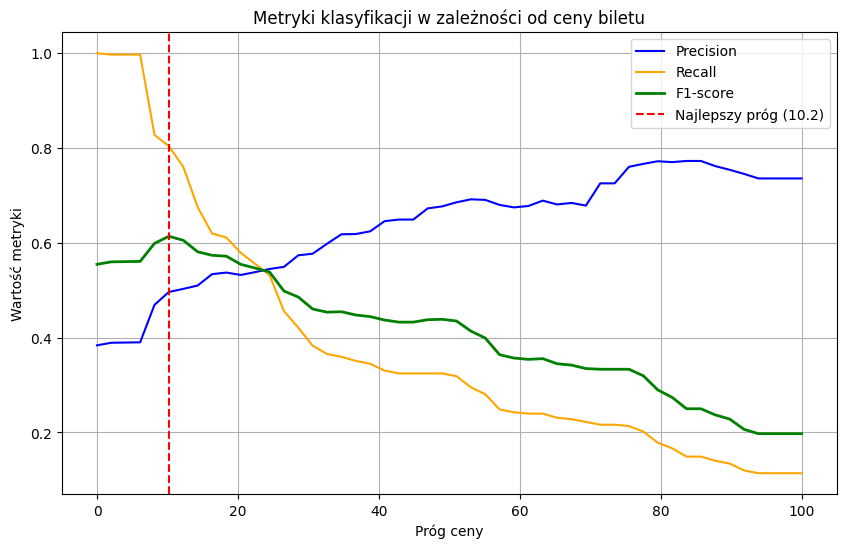

In [114]:
thresholds = np.linspace(0, 100, 50)
precisions, recalls, f1s = [], [], []

for t in thresholds:
    y_hat = (df_clean["fare"] >= t).astype(int).to_numpy()
    metrics = binary_metrics(y, y_hat)
    precisions.append(metrics["precision"])
    recalls.append(metrics["recall"])
    f1s.append(metrics["f1"])

best_idx = np.argmax(f1s)
best_t = thresholds[best_idx]
best_f1 = f1s[best_idx]

print(f"Najlepszy próg: {best_t:.2f} (F1 = {best_f1:.4f})")

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions, label="Precision", color="blue")
plt.plot(thresholds, recalls, label="Recall", color="orange")
plt.plot(thresholds, f1s, label="F1-score", color="green", linewidth=2)
plt.axvline(best_t, color="red", linestyle="--", label=f"Najlepszy próg ({best_t:.1f})")
plt.title("Metryki klasyfikacji w zależności od ceny biletu")
plt.xlabel("Próg ceny")
plt.ylabel("Wartość metryki")
plt.legend()
plt.grid(True)
plt.show()